# 07 - CRNN architecture variants: stride=2, residual blocks, GRU

Three isolated ablations against the current CRNN+CTC baseline
(`notebooks/05_baseline_crnn.ipynb`, regularized score 0.702), each changing
exactly one architectural piece and holding everything else (data split,
hyperparameters, training schedule) constant, per this project's
notebook-validate-before-wiring workflow:

1. **Stride=2 convolutions instead of `MaxPool2d`** (Springenberg et al. 2015,
   "Striving for Simplicity: The All Convolutional Net" — see RESOURCES.md).
2. **Residual blocks** around each CNN stage, downsampling unchanged (He et al.
   2015, "Deep Residual Learning for Image Recognition").
3. **BiGRU instead of BiLSTM** (Cho et al. 2014; Chung et al. 2014 empirical
   comparison).

The baseline is retrained fresh in this same notebook run (not compared
against the stale 0.702 from notebook 05) so all four numbers come from an
identical run of data loading, split, and training schedule. Each variant
trains separately (long-running — run these cells yourself and record the
printed scores) before deciding whether any of them beats the baseline
enough to replace `CRNN` as the reference model.

In [46]:
import sys
sys.path.append('..')

import copy
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F

from src.config import RANDOM_STATE, MODELS_DIR
from src.data import build_image_path, load_raw_data, split_train_val
from src.evaluate import combined_score

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [2]:
train = load_raw_data('train')
fit_df, val_df = split_train_val(train)

# Same fixed sample/seed as notebook 05, so these runs stay comparable to it.
val_sample = val_df.sample(120, random_state=RANDOM_STATE).reset_index(drop=True)
len(fit_df), len(val_df), len(val_sample)

(3280, 818, 120)

In [3]:
# Character vocabulary from the fit split (index 0 reserved for the CTC blank token)
chars = sorted(set(''.join(fit_df['Target'].tolist())))
BLANK = 0
char_to_idx = {c: i + 1 for i, c in enumerate(chars)}
idx_to_char = {i + 1: c for i, c in enumerate(chars)}
NUM_CLASSES = len(chars) + 1
NUM_CLASSES

82

In [4]:
TARGET_HEIGHT = 32
MAX_WIDTH = 1024


def load_and_resize(record_id):
    img = Image.open(build_image_path(record_id)).convert('L')
    w, h = img.size
    new_w = max(8, min(MAX_WIDTH, round(w * TARGET_HEIGHT / h)))
    img = img.resize((new_w, TARGET_HEIGHT), Image.BILINEAR)
    arr = (np.asarray(img, dtype=np.float32) / 255.0 - 0.5) / 0.5
    return torch.from_numpy(arr).unsqueeze(0)  # 1 x H x W

**Per-variant input-length formula.** CTC needs, for every sample, the exact
number of time steps `T` the CNN produces for that sample's (unpadded) width —
used both to mask padding out of the loss and to slice `greedy_decode`'s
output. The baseline's two `MaxPool2d(2, 2)` give the simple `(w // 2) // 2`
used in notebook 05. Swapping those for stride=2, padding=1, kernel=3 convs
(`CRNNStride2` below) changes that arithmetic — a real conv layer with
padding rounds differently than a kernel=2/stride=2/no-padding maxpool for
*odd* input widths (verified empirically: e.g. `w=101` gives `T=25` under
maxpool but `T=26` under the stride-2 convs). Reusing the naive formula for
that variant would silently hand CTC a wrong length for ~half the batch.
`stride2_output_len` below reproduces the stride-2 CNN's actual arithmetic;
the residual-block and GRU variants keep `MaxPool2d`, so they reuse the
baseline formula unchanged.

In [5]:
def naive_output_len(w):
    """Output width after the baseline's two MaxPool2d(2, 2) layers."""
    return (w // 2) // 2


def stride2_output_len(w):
    """Output width after CRNNStride2's two Conv2d(kernel=3, stride=2,
    padding=1) layers (replaces naive_output_len for that variant only)."""
    for _ in range(2):
        w = (w + 2 * 1 - 3) // 2 + 1
    return w

In [6]:
class LineDataset(Dataset):
    def __init__(self, df):
        self.ids = df['ID'].tolist()
        self.targets = df['Target'].tolist()

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = load_and_resize(self.ids[i])
        text = self.targets[i]
        label = torch.tensor([char_to_idx[c] for c in text], dtype=torch.long)
        return img, label, text


def make_collate_fn(output_len_fn):
    """Collate factory parametrized by the architecture's width-downsampling
    formula (see markdown note above), so each variant gets correct CTC
    input_lengths instead of assuming the baseline's maxpool arithmetic."""

    def collate_fn(batch):
        imgs, labels, texts = zip(*batch)
        widths = [im.shape[-1] for im in imgs]
        max_w = max(widths)
        padded = torch.zeros(len(imgs), 1, TARGET_HEIGHT, max_w)
        for i, im in enumerate(imgs):
            padded[i, :, :, : im.shape[-1]] = im
        input_lengths = torch.tensor([output_len_fn(w) for w in widths], dtype=torch.long)
        target_lengths = torch.tensor([len(l) for l in labels], dtype=torch.long)
        return padded, torch.cat(labels), input_lengths, target_lengths, texts

    return collate_fn


collate_fn = make_collate_fn(naive_output_len)
collate_fn_stride2 = make_collate_fn(stride2_output_len)

In [7]:
def greedy_decode(log_probs, input_lengths):
    """Argmax per time step, collapse repeats, drop blanks."""
    pred_idx = log_probs.argmax(2)
    texts = []
    for b in range(pred_idx.size(0)):
        seq = pred_idx[b, : input_lengths[b]].tolist()
        out, prev = [], None
        for idx in seq:
            if idx != prev and idx != BLANK:
                out.append(idx_to_char[idx])
            prev = idx
        texts.append(''.join(out))
    return texts

## Model variants

In [8]:
class CRNN(nn.Module):
    """Baseline: CNN + BiLSTM + CTC head (Shi, Bai & Yao 2015), see
    RESOURCES.md. Identical to notebooks/05_baseline_crnn.ipynb's CRNN,
    retrained fresh here so the comparison is same-run."""

    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, 1, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d((2, 1)),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 128, 3, 1, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d((2, 1)),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 256, (2, 1), 1, 0), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.rnn = nn.LSTM(256, 128, num_layers=2, bidirectional=True, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        feat = self.cnn(x)  # B x C x 1 x W'
        feat = feat.squeeze(2).permute(0, 2, 1)  # B x W' x C
        seq, _ = self.rnn(feat)
        seq = self.dropout(seq)
        return self.fc(seq).log_softmax(2)  # B x W' x num_classes

In [9]:
class CRNNStride2(nn.Module):
    """Variant 1: every MaxPool2d replaced by an equivalent-stride
    convolution (kernel=3, stride matching the pool it replaces, padding=1)
    (Springenberg et al. 2015 - see RESOURCES.md), so downsampling is
    learned instead of a fixed max. Everything else (channel sizes, RNN,
    dropout placement) identical to the baseline CRNN."""

    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, 2, 1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 2, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 3, (2, 1), 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 128, 3, (2, 1), 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 256, (2, 1), 1, 0), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.rnn = nn.LSTM(256, 128, num_layers=2, bidirectional=True, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        feat = self.cnn(x)
        feat = feat.squeeze(2).permute(0, 2, 1)
        seq, _ = self.rnn(feat)
        seq = self.dropout(seq)
        return self.fc(seq).log_softmax(2)

In [10]:
class ResidualBlock(nn.Module):
    """Basic residual block (He et al. 2015 - see RESOURCES.md): two 3x3
    convs with a skip connection; a 1x1 conv projects the shortcut when the
    channel count changes."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, 1, 1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.shortcut = (
            nn.Sequential(nn.Conv2d(in_channels, out_channels, 1), nn.BatchNorm2d(out_channels))
            if in_channels != out_channels else nn.Identity()
        )

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class CRNNResidual(nn.Module):
    """Variant 2: each conv block wrapped in a ResidualBlock; MaxPool2d
    downsampling left unchanged so this isolates the residual-connection
    effect from the pooling/stride experiment above. Everything else
    identical to the baseline CRNN."""

    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        self.cnn = nn.Sequential(
            ResidualBlock(1, 32), nn.MaxPool2d(2, 2),
            ResidualBlock(32, 64), nn.MaxPool2d(2, 2),
            ResidualBlock(64, 128), nn.MaxPool2d((2, 1)),
            nn.Dropout2d(dropout),
            ResidualBlock(128, 128), nn.MaxPool2d((2, 1)),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 256, (2, 1), 1, 0), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.rnn = nn.LSTM(256, 128, num_layers=2, bidirectional=True, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        feat = self.cnn(x)
        feat = feat.squeeze(2).permute(0, 2, 1)
        seq, _ = self.rnn(feat)
        seq = self.dropout(seq)
        return self.fc(seq).log_softmax(2)

In [11]:
class CRNNGRU(nn.Module):
    """Variant 3: BiLSTM replaced by a BiGRU (Cho et al. 2014; Chung et al.
    2014 - see RESOURCES.md), isolating the recurrent-cell-type effect from
    the CNN backbone, which is identical to the baseline CRNN."""

    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, 1, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d((2, 1)),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 128, 3, 1, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d((2, 1)),
            nn.Dropout2d(dropout),
            nn.Conv2d(128, 256, (2, 1), 1, 0), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.rnn = nn.GRU(256, 128, num_layers=2, bidirectional=True, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        feat = self.cnn(x)
        feat = feat.squeeze(2).permute(0, 2, 1)
        seq, _ = self.rnn(feat)
        seq = self.dropout(seq)
        return self.fc(seq).log_softmax(2)

**Smoke test (CPU, no training).** Checks every variant's forward pass
produces the expected shape and that each collate function's `input_lengths`
matches the model's actual output width, for both even and odd image
widths — before spending GPU time on any of them.

In [12]:
def smoke_test(model_cls, collate, output_len_fn, name):
    model = model_cls(NUM_CLASSES).eval()
    for w in [64, 101, 250, 251]:
        x = torch.randn(2, 1, TARGET_HEIGHT, w)
        with torch.no_grad():
            out = model(x)
        actual_T = out.shape[1]
        expected_T = output_len_fn(w)
        status = "OK" if actual_T == expected_T else "MISMATCH"
        print(f"{name:14s} w={w:4d} -> T={actual_T:3d} (expected {expected_T:3d}) [{status}]")
        assert actual_T == expected_T, f"{name}: length formula does not match model output at w={w}"
    print(f"{name}: smoke test passed\n")


smoke_test(CRNN, collate_fn, naive_output_len, "CRNN")
smoke_test(CRNNStride2, collate_fn_stride2, stride2_output_len, "CRNNStride2")
smoke_test(CRNNResidual, collate_fn, naive_output_len, "CRNNResidual")
smoke_test(CRNNGRU, collate_fn, naive_output_len, "CRNNGRU")

CRNN           w=  64 -> T= 16 (expected  16) [OK]
CRNN           w= 101 -> T= 25 (expected  25) [OK]
CRNN           w= 250 -> T= 62 (expected  62) [OK]
CRNN           w= 251 -> T= 62 (expected  62) [OK]
CRNN: smoke test passed

CRNNStride2    w=  64 -> T= 16 (expected  16) [OK]
CRNNStride2    w= 101 -> T= 26 (expected  26) [OK]
CRNNStride2    w= 250 -> T= 63 (expected  63) [OK]
CRNNStride2    w= 251 -> T= 63 (expected  63) [OK]
CRNNStride2: smoke test passed

CRNNResidual   w=  64 -> T= 16 (expected  16) [OK]
CRNNResidual   w= 101 -> T= 25 (expected  25) [OK]
CRNNResidual   w= 250 -> T= 62 (expected  62) [OK]
CRNNResidual   w= 251 -> T= 62 (expected  62) [OK]
CRNNResidual: smoke test passed

CRNNGRU        w=  64 -> T= 16 (expected  16) [OK]
CRNNGRU        w= 101 -> T= 25 (expected  25) [OK]
CRNNGRU        w= 250 -> T= 62 (expected  62) [OK]
CRNNGRU        w= 251 -> T= 62 (expected  62) [OK]
CRNNGRU: smoke test passed



## Shared train/eval harness

In [42]:
def evaluate(model, loader):
    model.eval()
    refs, hyps = [], []
    with torch.no_grad():
        for imgs, targets_cat, input_lengths, target_lengths, texts in loader:
            imgs = imgs.to(device)
            log_probs = model(imgs)
            preds = greedy_decode(log_probs.cpu(), input_lengths)
            refs.extend(texts)
            hyps.extend(preds)
    model.train()
    return combined_score(refs, hyps)


def train_with_early_stopping(model, optimizer, fit_dl, val_dl, max_epochs, patience,
                               scheduler=None, initial_best_score=-1.0):
    """Trains until max_epochs or patience epochs pass with no val-score
    improvement (Prechelt 1998, see RESOURCES.md); returns the best
    checkpoint. `initial_best_score` lets a continuation run only count an
    epoch as an improvement if it beats an already-known reference (e.g. a
    loaded checkpoint's score) - best_epoch=0 means no epoch in this run
    beat initial_best_score, same convention as notebook 05."""
    t0 = time.time()
    history = []
    best_score = initial_best_score
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    epochs_since_improvement = 0

    for epoch in range(1, max_epochs + 1):
        total_loss = 0.0
        n = 0
        for imgs, targets_cat, input_lengths, target_lengths, texts in fit_dl:
            imgs = imgs.to(device)
            optimizer.zero_grad()
            log_probs = model(imgs)
            loss = ctc_loss(log_probs.permute(1, 0, 2), targets_cat, input_lengths, target_lengths)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            n += imgs.size(0)
        train_loss = total_loss / n

        score = evaluate(model, val_dl)
        history.append({'epoch': epoch, 'train_loss': train_loss, **score})
        current_lr = optimizer.param_groups[0]['lr']
        print(f"epoch {epoch:2d} | lr {current_lr:.2e} | loss {train_loss:.3f} | val CER {score['cer_weighted']:.3f} "
              f"WER {score['wer_weighted']:.3f} final {score['score']:.3f} | {time.time()-t0:.0f}s")

        if scheduler is not None:
            scheduler.step()

        if score['score'] > best_score:
            best_score = score['score']
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_since_improvement = 0
        else:
            epochs_since_improvement += 1
            if epochs_since_improvement >= patience:
                print(f"Early stopping at epoch {epoch} (no improvement for {patience} epochs)")
                break

    return best_state, best_score, best_epoch, history

In [18]:
DROPOUT = 0.2
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 50
PATIENCE = 8


fit_ds = LineDataset(fit_df)
val_ds = LineDataset(val_sample)

fit_dl = DataLoader(fit_ds, batch_size=32, shuffle=True, collate_fn=collate_fn)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False, collate_fn=collate_fn)

# CRNNStride2 needs the stride-2-aware collate (see markdown note above).
fit_dl_stride2 = DataLoader(fit_ds, batch_size=32, shuffle=True, collate_fn=collate_fn_stride2)
val_dl_stride2 = DataLoader(val_ds, batch_size=32, shuffle=False, collate_fn=collate_fn_stride2)

ctc_loss = nn.CTCLoss(blank=BLANK, zero_infinity=True)

results = {}

## 0. Baseline (recomputed this run)

Same architecture as `notebooks/05_baseline_crnn.ipynb`, trained fresh here so
every variant below is compared against a same-run number, not the stale
0.702 recorded there (per this project's evaluation-gate rule).

In [19]:
torch.manual_seed(RANDOM_STATE)
model_baseline = CRNN(NUM_CLASSES, dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(model_baseline.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_baseline, optimizer, fit_dl, val_dl, max_epochs=MAX_EPOCHS, patience=PATIENCE
)
model_baseline.load_state_dict(best_state)
results['baseline'] = evaluate(model_baseline, val_dl)
print(f"baseline best epoch: {best_epoch} | score: {results['baseline']['score']:.3f}")

epoch  1 | loss 3.376 | val CER 61.292 WER 11.125 final -0.021 | 19s
epoch  2 | loss 3.090 | val CER 61.292 WER 11.125 final -0.021 | 38s
epoch  3 | loss 3.038 | val CER 57.533 WER 11.125 final 0.013 | 58s
epoch  4 | loss 2.593 | val CER 46.292 WER 10.825 final 0.128 | 78s
epoch  5 | loss 2.182 | val CER 33.308 WER 10.208 final 0.272 | 99s
epoch  6 | loss 1.837 | val CER 26.325 WER 9.517 final 0.364 | 119s
epoch  7 | loss 1.574 | val CER 23.242 WER 8.992 final 0.414 | 140s
epoch  8 | loss 1.403 | val CER 22.933 WER 8.708 final 0.429 | 161s
epoch  9 | loss 1.277 | val CER 19.975 WER 8.142 final 0.479 | 181s
epoch 10 | loss 1.178 | val CER 18.317 WER 7.875 final 0.505 | 202s
epoch 11 | loss 1.099 | val CER 17.400 WER 7.525 final 0.528 | 223s
epoch 12 | loss 1.035 | val CER 17.925 WER 7.725 final 0.515 | 243s
epoch 13 | loss 0.975 | val CER 15.925 WER 7.308 final 0.551 | 264s
epoch 14 | loss 0.923 | val CER 15.717 WER 7.050 final 0.563 | 285s
epoch 15 | loss 0.882 | val CER 14.433 WER 6.9

## 1. Variant: stride=2 instead of MaxPool2d

In [17]:
torch.manual_seed(RANDOM_STATE)
model_stride2 = CRNNStride2(NUM_CLASSES, dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(model_stride2.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_stride2, optimizer, fit_dl_stride2, val_dl_stride2, max_epochs=MAX_EPOCHS, patience=PATIENCE
)
model_stride2.load_state_dict(best_state)
results['stride2'] = evaluate(model_stride2, val_dl_stride2)
print(f"stride2 best epoch: {best_epoch} | score: {results['stride2']['score']:.3f} "
      f"(baseline {results['baseline']['score']:.3f}, delta {results['stride2']['score'] - results['baseline']['score']:+.3f})")

epoch  1 | loss 3.373 | val CER 61.292 WER 11.125 final -0.021 | 19s
epoch  2 | loss 3.104 | val CER 61.292 WER 11.125 final -0.021 | 39s
epoch  3 | loss 3.088 | val CER 61.158 WER 11.117 final -0.019 | 59s
epoch  4 | loss 3.008 | val CER 52.392 WER 11.117 final 0.061 | 79s
epoch  5 | loss 2.577 | val CER 42.433 WER 10.792 final 0.165 | 99s
epoch  6 | loss 2.260 | val CER 37.458 WER 10.275 final 0.231 | 119s
epoch  7 | loss 2.027 | val CER 30.800 WER 9.783 final 0.312 | 138s
epoch  8 | loss 1.820 | val CER 28.933 WER 9.483 final 0.342 | 157s
epoch  9 | loss 1.661 | val CER 26.583 WER 9.075 final 0.380 | 176s
epoch 10 | loss 1.536 | val CER 24.442 WER 8.908 final 0.407 | 195s
epoch 11 | loss 1.428 | val CER 22.492 WER 8.467 final 0.443 | 214s
epoch 12 | loss 1.335 | val CER 21.767 WER 8.358 final 0.454 | 234s
epoch 13 | loss 1.267 | val CER 20.475 WER 7.975 final 0.482 | 252s
epoch 14 | loss 1.195 | val CER 19.950 WER 7.775 final 0.495 | 271s
epoch 15 | loss 1.142 | val CER 18.967 WER 7

In [22]:
results['stride2'] = {'wer_weighted': 5.917,'cer_weighted':13.250,'score': 0.633}
results

{'baseline': {'wer_weighted': 5.241666666666666,
  'cer_weighted': 10.016666666666667,
  'score': 0.6905366161616162},
 'stride2': {'wer_weighted': 5.917, 'cer_weighted': 13.25, 'score': 0.633}}

## 2. Variant: Residual blocks

In [23]:
torch.manual_seed(RANDOM_STATE)
model_residual = CRNNResidual(NUM_CLASSES, dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(model_residual.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_residual, optimizer, fit_dl, val_dl, max_epochs=MAX_EPOCHS, patience=PATIENCE
)
model_residual.load_state_dict(best_state)
results['residual'] = evaluate(model_residual, val_dl)
print(f"residual best epoch: {best_epoch} | score: {results['residual']['score']:.3f} "
      f"(baseline {results['baseline']['score']:.3f}, delta {results['residual']['score'] - results['baseline']['score']:+.3f})")

epoch  1 | loss 3.349 | val CER 61.292 WER 11.125 final -0.021 | 24s
epoch  2 | loss 3.088 | val CER 61.292 WER 11.125 final -0.021 | 50s
epoch  3 | loss 3.003 | val CER 52.350 WER 11.125 final 0.061 | 75s
epoch  4 | loss 2.458 | val CER 40.883 WER 10.533 final 0.189 | 99s
epoch  5 | loss 1.921 | val CER 28.050 WER 9.833 final 0.335 | 124s
epoch  6 | loss 1.510 | val CER 21.958 WER 8.750 final 0.436 | 148s
epoch  7 | loss 1.246 | val CER 19.017 WER 8.108 final 0.489 | 173s
epoch  8 | loss 1.083 | val CER 17.500 WER 7.642 final 0.523 | 198s
epoch  9 | loss 0.963 | val CER 15.775 WER 7.317 final 0.552 | 222s
epoch 10 | loss 0.866 | val CER 15.250 WER 7.308 final 0.557 | 246s
epoch 11 | loss 0.785 | val CER 13.942 WER 6.867 final 0.587 | 271s
epoch 12 | loss 0.726 | val CER 12.975 WER 6.600 final 0.607 | 295s
epoch 13 | loss 0.672 | val CER 13.458 WER 6.675 final 0.600 | 320s
epoch 14 | loss 0.619 | val CER 12.292 WER 6.092 final 0.634 | 344s
epoch 15 | loss 0.581 | val CER 11.425 WER 5.8

## 3. Variant: GRU instead of LSTM

In [24]:
torch.manual_seed(RANDOM_STATE)
model_gru = CRNNGRU(NUM_CLASSES, dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(model_gru.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_gru, optimizer, fit_dl, val_dl, max_epochs=MAX_EPOCHS, patience=PATIENCE
)
model_gru.load_state_dict(best_state)
results['gru'] = evaluate(model_gru, val_dl)
print(f"gru best epoch: {best_epoch} | score: {results['gru']['score']:.3f} "
      f"(baseline {results['baseline']['score']:.3f}, delta {results['gru']['score'] - results['baseline']['score']:+.3f})")

epoch  1 | loss 3.267 | val CER 61.292 WER 11.125 final -0.021 | 19s
epoch  2 | loss 3.051 | val CER 54.950 WER 11.125 final 0.037 | 38s
epoch  3 | loss 2.514 | val CER 43.383 WER 10.575 final 0.165 | 58s
epoch  4 | loss 2.013 | val CER 28.850 WER 9.875 final 0.326 | 77s
epoch  5 | loss 1.629 | val CER 23.408 WER 8.833 final 0.419 | 98s
epoch  6 | loss 1.390 | val CER 20.792 WER 8.167 final 0.471 | 119s
epoch  7 | loss 1.233 | val CER 18.667 WER 7.917 final 0.500 | 140s
epoch  8 | loss 1.114 | val CER 17.233 WER 7.650 final 0.525 | 160s
epoch  9 | loss 1.027 | val CER 16.817 WER 7.458 final 0.536 | 180s
epoch 10 | loss 0.952 | val CER 15.500 WER 6.950 final 0.570 | 201s
epoch 11 | loss 0.886 | val CER 14.825 WER 6.825 final 0.581 | 222s
epoch 12 | loss 0.840 | val CER 15.142 WER 6.925 final 0.574 | 242s
epoch 13 | loss 0.799 | val CER 13.908 WER 6.458 final 0.604 | 263s
epoch 14 | loss 0.759 | val CER 13.492 WER 6.342 final 0.613 | 283s
epoch 15 | loss 0.717 | val CER 13.092 WER 6.133 

## Summary

Compare all four same-run scores, then update `README.md`'s Progress log for
each: variants that beat the baseline are candidates to replace `CRNN` as the
reference model (still needs a qualitative check on a few decoded lines, not
just the number, per this project's gate); variants that don't win get logged
as negative results and left uncommitted to `src/`.

In [25]:
summary = pd.DataFrame([
    {'variant': name, **score} for name, score in results.items()
]).sort_values('score', ascending=False)
summary

,variant,wer_weighted,cer_weighted,score
2,residual,4.758333,8.991667,0.719994
3,gru,5.083333,10.141667,0.695997
0,baseline,5.241667,10.016667,0.690537
1,stride2,5.917000,13.250000,0.633000


In [26]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
torch.save({
    'model_state_dict': model_residual.state_dict(),  # ya tiene cargado el best_state de la época 47
    'char_to_idx': char_to_idx,
    'idx_to_char': idx_to_char,
    'target_height': TARGET_HEIGHT,
    'max_width': MAX_WIDTH,
}, MODELS_DIR / 'crnn_residual.pt')

In [27]:
model_residual.eval()
with torch.no_grad():
    imgs, targets_cat, input_lengths, target_lengths, texts = next(iter(val_dl))
    imgs = imgs.to(device)
    preds = greedy_decode(model_residual(imgs).cpu(), input_lengths)
for pred, ref in list(zip(preds, texts))[:8]:
    print(f"pred: {pred!r}")
    print(f"ref:  {ref!r}")
    print()

pred: 'mear the Toone of St Michraills in the Island of Barbacosmis'
ref:  'near the Towne of St Michaells in the Island of Barbados next'

pred: 'personally appeered before me the within named'
ref:  'personally appeared before me the within named'

pred: 'the per Iner abovenentioned, ever have had , hed or Endtiore'
ref:  'the persones above mentioned, ever have had, or Enjoyed'

pred: 'other pte Witnesseth that the aforesd Major Portesgue for & in~'
ref:  'other pte Witnesseth that the aforesd Major Fortesque for & in ~'

pred: 'ins the said Capt Geonge stanfast and Robert permings his athrneygs Geniall and'
ref:  'us the said Capt George Stanfast and Robert Jenning his attorney Genall and'

pred: 'To all Christian people to whom these pnts shall come'
ref:  'To all Christian people to whom these pnts shall come'

pred: 'roleafed giut cleynme and for sver confirmed and by thesd wrese nts by'
ref:  'released quit clayme and for ever confirmed and by these by presents by-'

pred: 'wch

In [33]:
torch.manual_seed(RANDOM_STATE)
model_residual_cosine = CRNNResidual(NUM_CLASSES, dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(model_residual_cosine.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)

best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_residual_cosine, optimizer, fit_dl, val_dl, max_epochs=MAX_EPOCHS, patience=PATIENCE,
    scheduler=scheduler
)
model_residual_cosine.load_state_dict(best_state)
results['residual_cosine'] = evaluate(model_residual_cosine, val_dl)
print(f"residual+cosine best epoch: {best_epoch} | score: {results['residual_cosine']['score']:.3f} "
      f"(residual constant-LR was {results['residual']['score']:.3f}, "
      f"delta {results['residual_cosine']['score'] - results['residual']['score']:+.3f})")

epoch  1 | lr 1.00e-03 | loss 3.349 | val CER 61.292 WER 11.125 final -0.021 | 24s
epoch  2 | lr 9.99e-04 | loss 3.088 | val CER 61.292 WER 11.125 final -0.021 | 49s
epoch  3 | lr 9.96e-04 | loss 3.007 | val CER 54.375 WER 11.125 final 0.042 | 75s
epoch  4 | lr 9.91e-04 | loss 2.469 | val CER 39.942 WER 10.358 final 0.205 | 100s
epoch  5 | lr 9.84e-04 | loss 1.913 | val CER 26.850 WER 9.492 final 0.360 | 125s
epoch  6 | lr 9.76e-04 | loss 1.490 | val CER 21.933 WER 8.742 final 0.436 | 150s
epoch  7 | lr 9.65e-04 | loss 1.232 | val CER 18.675 WER 8.108 final 0.492 | 176s
epoch  8 | lr 9.52e-04 | loss 1.077 | val CER 18.392 WER 7.983 final 0.500 | 201s
epoch  9 | lr 9.38e-04 | loss 0.965 | val CER 15.142 WER 7.125 final 0.565 | 225s
epoch 10 | lr 9.22e-04 | loss 0.863 | val CER 14.542 WER 6.950 final 0.578 | 250s
epoch 11 | lr 9.05e-04 | loss 0.786 | val CER 13.683 WER 6.792 final 0.593 | 276s
epoch 12 | lr 8.85e-04 | loss 0.728 | val CER 12.883 WER 6.558 final 0.610 | 301s
epoch 13 | lr

In [ ]:
import random 
import torchvision.transforms.functional as TF

class AugmentedLineDataset(Dataset):
    """Same as LineDataset, but with light geometric/intensity augmentation
    applied every time an item is fetched - slight rotation, brightness/
    contrast jitter, additive Gaussian noise (Wigington et al. 2017, ICDAR -
    see RESOURCES.md), to reduce overfitting on this project's relatively
    small (3,280-row) fit split. Train-time only - val_ds stays a plain
    LineDataset. Rotation uses expand=False so width/height are unchanged,
    so collate_fn's CTC input_lengths formula still applies unmodified."""

    def __init__(self, df):
        self.ids = df['ID'].tolist()
        self.targets = df['Target'].tolist()

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = load_and_resize(self.ids[i])  # 1 x H x W, normalized to [-1, 1]

        angle = random.uniform(-3, 3)
        img = TF.rotate(img, angle, fill=-1.0)

        brightness = random.uniform(0.85, 1.15)
        contrast = random.uniform(0.85, 1.15)
        img = (img - img.mean()) * contrast + img.mean()
        img = (img * brightness).clamp(-1.0, 1.0)

        img = (img + torch.randn_like(img) * 0.03).clamp(-1.0, 1.0)

        text = self.targets[i]
        label = torch.tensor([char_to_idx[c] for c in text], dtype=torch.long)
        return img, label, text


fit_ds_aug = AugmentedLineDataset(fit_df)
fit_dl_aug = DataLoader(fit_ds_aug, batch_size=32, shuffle=True, collate_fn=collate_fn)

In [35]:
torch.manual_seed(RANDOM_STATE)
model_residual_aug = CRNNResidual(NUM_CLASSES, dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(model_residual_aug.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_residual_aug, optimizer, fit_dl_aug, val_dl, max_epochs=MAX_EPOCHS, patience=PATIENCE
)
model_residual_aug.load_state_dict(best_state)
results['residual_aug'] = evaluate(model_residual_aug, val_dl)
print(f"residual+aug best epoch: {best_epoch} | score: {results['residual_aug']['score']:.3f} "
      f"(residual no-aug was {results['residual']['score']:.3f}, "
      f"delta {results['residual_aug']['score'] - results['residual']['score']:+.3f})")

epoch  1 | lr 1.00e-03 | loss 3.354 | val CER 61.292 WER 11.125 final -0.021 | 30s
epoch  2 | lr 1.00e-03 | loss 3.091 | val CER 61.292 WER 11.125 final -0.021 | 61s
epoch  3 | lr 1.00e-03 | loss 3.081 | val CER 61.042 WER 11.108 final -0.018 | 93s
epoch  4 | lr 1.00e-03 | loss 2.966 | val CER 48.800 WER 11.117 final 0.093 | 125s
epoch  5 | lr 1.00e-03 | loss 2.507 | val CER 40.883 WER 10.625 final 0.186 | 159s
epoch  6 | lr 1.00e-03 | loss 2.081 | val CER 29.858 WER 9.867 final 0.317 | 193s
epoch  7 | lr 1.00e-03 | loss 1.690 | val CER 23.092 WER 8.858 final 0.421 | 227s
epoch  8 | lr 1.00e-03 | loss 1.463 | val CER 20.267 WER 8.308 final 0.470 | 260s
epoch  9 | lr 1.00e-03 | loss 1.316 | val CER 19.000 WER 7.875 final 0.499 | 293s
epoch 10 | lr 1.00e-03 | loss 1.200 | val CER 16.683 WER 7.458 final 0.538 | 326s
epoch 11 | lr 1.00e-03 | loss 1.114 | val CER 15.242 WER 6.942 final 0.572 | 361s
epoch 12 | lr 1.00e-03 | loss 1.037 | val CER 15.817 WER 7.258 final 0.554 | 394s
epoch 13 | 

In [36]:
model_residual_aug.eval()
with torch.no_grad():
    imgs, targets_cat, input_lengths, target_lengths, texts = next(iter(val_dl))
    imgs = imgs.to(device)
    preds = greedy_decode(model_residual_aug(imgs).cpu(), input_lengths)
for pred, ref in list(zip(preds, texts))[:8]:
    print(f"pred: {pred!r}")
    print(f"ref:  {ref!r}")
    print()

pred: 'near the Powne of St ichaitls in the Island of Barbadosnxt'
ref:  'near the Towne of St Michaells in the Island of Barbados next'

pred: 'personally appeared before me the within named'
ref:  'personally appeared before me the within named'

pred: 'the perstnes abovenentrined, ever have had , hed a Ensiope'
ref:  'the persones above mentioned, ever have had, or Enjoyed'

pred: 'other pt Witnesseth that the aforesd Major Portesgne for & in'
ref:  'other pte Witnesseth that the aforesd Major Fortesque for & in ~'

pred: 'us the said Capt George Htanfart and Robert Jenning his attiomeys Genall and'
ref:  'us the said Capt George Stanfast and Robert Jenning his attorney Genall and'

pred: 'To all Christian people to whom these pnts shall come'
ref:  'To all Christian people to whom these pnts shall come'

pred: 'relecfedgint clayme and for ever confirmed and by theed wresentt by'
ref:  'released quit clayme and for ever confirmed and by these by presents by-'

pred: 'who uson theire

In [37]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
torch.save({
    'model_state_dict': model_residual_aug.state_dict(),
    'char_to_idx': char_to_idx,
    'idx_to_char': idx_to_char,
    'target_height': TARGET_HEIGHT,
    'max_width': MAX_WIDTH,
}, MODELS_DIR / 'crnn_residual_aug.pt')

In [38]:
from rapidfuzz.distance import Levenshtein
from src.data import build_image_path

model_residual_aug.eval()
refs, hyps = [], []
with torch.no_grad():
    for imgs, targets_cat, input_lengths, target_lengths, texts in val_dl:
        imgs = imgs.to(device)
        preds = greedy_decode(model_residual_aug(imgs).cpu(), input_lengths)
        refs.extend(texts)
        hyps.extend(preds)

rows = []
for record_id, ref, hyp in zip(val_sample['ID'], refs, hyps):
    img = Image.open(build_image_path(record_id))
    w, h = img.size
    cer_raw = Levenshtein.distance(ref, hyp)
    rows.append({
        'ID': record_id, 'ref': ref, 'pred': hyp,
        'cer_raw': cer_raw, 'cer_norm': cer_raw / max(len(ref), 1),
        'ref_len': len(ref), 'img_w': w, 'img_h': h, 'aspect_ratio': round(w / h, 1),
    })

error_df = pd.DataFrame(rows).sort_values('cer_raw', ascending=False).reset_index(drop=True)
error_df.head(15)

,ID,ref,pred,cer_raw,cer_norm,ref_len,img_w,img_h,aspect_ratio
0,VfA8Rllc17Tz2PUR,two Sales bearing date and w^th these adults a...,hwor hales beaveing d at rona the erdntr and a...,38,0.431818,88,5634,433,13.0
1,gT7S2CnDnp1MEZOQ,One .^th Appearer then and there did .... a co...,Aoleh eterg io they and there didg tist ^h Cer...,31,0.525424,59,1204,115,10.5
2,2OdfQFZuXk2k2ELW,ed the Masters and owners of Shipps Employed i...,Tthe Bateres and onwnery of thert Cnptond in t...,30,0.405405,74,5348,381,14.0
3,FBafS13DwW9hTVI4,hereafter haue or make claime Challeng or dema...,bnesin tawe mall thaie Calang & derard in i t,30,0.535714,56,4480,520,8.6
4,8WRAnp0vSrlaT5vb,"Three Coppers, Two , two ladles, one head...","Dares Coppert, dwo Scumnerd, two ladles, one s...",24,0.452830,53,4073,233,17.5
5,mesbSOn5eKS1hzBA,n:grow legg and Joane and Little Robin guien T...,wearce bely and Seave and Titte Reein given Co...,22,0.431373,51,4528,472,9.6
6,MiEx2OkmrdGFcWxA,the terme afores^d be Sold Conveyed Disposed o...,the torne aforesed he ad Carcayed Essered on hir,21,0.403846,52,4723,425,11.1
7,9nTzbpXAGbGPvJQG,of our Lord God one thousand six hundred seven...,Iupoae Lod Andon housand Sxbundred Seventy & f ue,19,0.339286,56,4570,528,8.7
8,TYxkNBqpOuiigEmi,bee found This funerall right and charges toge...,toe faund this fioves acraigth and charges tigher,18,0.360000,50,4561,431,10.6
9,luDC7yIL1KOSFTEZ,Containeing by Estimacon one Hundred and Eight...,containeing y Esticncoen one undre d and dyene...,18,0.339623,53,4176,324,12.9


In [39]:
for _, row in error_df.head(10).iterrows():
    print(f"ID={row['ID']} | cer_raw={row['cer_raw']} cer_norm={row['cer_norm']:.2f} "
          f"| img {row['img_w']}x{row['img_h']} (ar={row['aspect_ratio']}) | ref_len={row['ref_len']}")
    print(f"  pred: {row['pred']!r}")
    print(f"  ref:  {row['ref']!r}")
    print()



ID=VfA8Rllc17Tz2PUR | cer_raw=38 cer_norm=0.43 | img 5634x433 (ar=13.0) | ref_len=88
  pred: 'hwor hales beaveing d at rona the erdntr and al he degas and Chotly Eondeirgs'
  ref:  'two Sales bearing date and w^th these adults and all the mograge Land Chattles buildings'

ID=gT7S2CnDnp1MEZOQ | cer_raw=31 cer_norm=0.53 | img 1204x115 (ar=10.5) | ref_len=59
  pred: 'Aoleh eterg io they and there didg tist ^h Certine with of'
  ref:  'One .^th Appearer then and there did .... a contain bill of'

ID=2OdfQFZuXk2k2ELW | cer_raw=30 cer_norm=0.41 | img 5348x381 (ar=14.0) | ref_len=74
  pred: 'Tthe Bateres and onwnery of thert Cnptond in the sSaid Jugand forivie'
  ref:  'ed the Masters and owners of Shipps Employed in the said Companies service'

ID=FBafS13DwW9hTVI4 | cer_raw=30 cer_norm=0.54 | img 4480x520 (ar=8.6) | ref_len=56
  pred: 'bnesin tawe mall thaie Calang & derard in i t'
  ref:  'hereafter haue or make claime Challeng or demand any rig'

ID=8WRAnp0vSrlaT5vb | cer_raw=24 cer_norm=0

In [40]:
error_df[['cer_raw', 'cer_norm', 'ref_len', 'img_w', 'img_h', 'aspect_ratio']].corr()['cer_norm']

cer_raw         0.960583
cer_norm        1.000000
ref_len        -0.192222
img_w           0.592930
img_h           0.642510
aspect_ratio   -0.504637
Name: cer_norm, dtype: float64

ID=VfA8Rllc17Tz2PUR | pred: 'hwor hales beaveing d at rona the erdntr and al he degas and Chotly Eondeirgs'
  ref: 'two Sales bearing date and w^th these adults and all the mograge Land Chattles buildings'


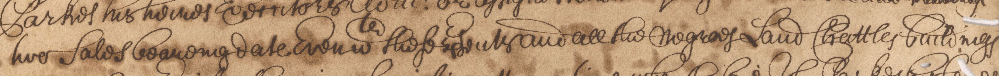

ID=gT7S2CnDnp1MEZOQ | pred: 'Aoleh eterg io they and there didg tist ^h Certine with of'
  ref: 'One .^th Appearer then and there did .... a contain bill of'


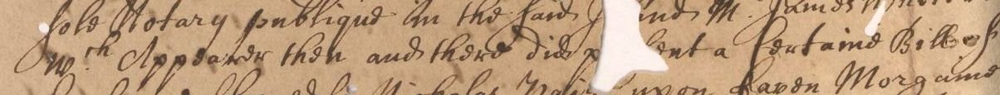

ID=2OdfQFZuXk2k2ELW | pred: 'Tthe Bateres and onwnery of thert Cnptond in the sSaid Jugand forivie'
  ref: 'ed the Masters and owners of Shipps Employed in the said Companies service'


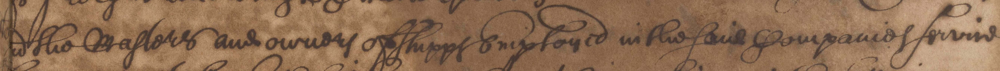

ID=FBafS13DwW9hTVI4 | pred: 'bnesin tawe mall thaie Calang & derard in i t'
  ref: 'hereafter haue or make claime Challeng or demand any rig'


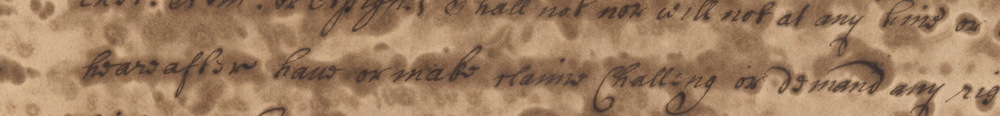

ID=8WRAnp0vSrlaT5vb | pred: 'Dares Coppert, dwo Scumnerd, two ladles, one still wt head eworad'
  ref: 'Three Coppers, Two  , two ladles, one     head& worms'


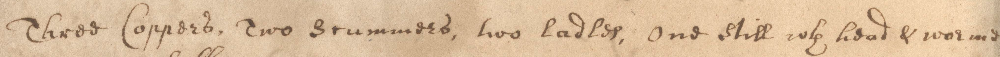

In [41]:
from IPython.display import display

for _, row in error_df.head(5).iterrows():
    print(f"ID={row['ID']} | pred: {row['pred']!r}")
    print(f"  ref: {row['ref']!r}")
    display(Image.open(build_image_path(row['ID'])))

In [43]:
def gaussian_kernel1d(sigma, radius=None):
    if radius is None:
        radius = max(1, int(3 * sigma))
    x = torch.arange(-radius, radius + 1, dtype=torch.float32)
    kernel = torch.exp(-(x ** 2) / (2 * sigma ** 2))
    return kernel / kernel.sum()


def gaussian_blur_2d(field, sigma):
    kernel = gaussian_kernel1d(sigma)
    radius = kernel.numel() // 2
    field = F.conv2d(field, kernel.view(1, 1, 1, -1), padding=(0, radius))
    field = F.conv2d(field, kernel.view(1, 1, -1, 1), padding=(radius, 0))
    return field


def elastic_distort(img, alpha=12.0, sigma=4.0):
    """Simard, Steinkraus & Platt (2003) elastic distortion - see RESOURCES.md.
    img: 1 x H x W tensor. Warps the image via a random, Gaussian-smoothed
    displacement field (bilinear resample), simulating natural handwriting
    stroke variability - complements the affine rotation/brightness/noise
    already in AugmentedLineDataset rather than replacing them. Verified:
    alpha=0 reproduces the input exactly; output shape always matches input."""
    _, H, W = img.shape
    dx = gaussian_blur_2d((torch.rand(1, 1, H, W) * 2 - 1), sigma) * alpha
    dy = gaussian_blur_2d((torch.rand(1, 1, H, W) * 2 - 1), sigma) * alpha

    yy, xx = torch.meshgrid(
        torch.arange(H, dtype=torch.float32), torch.arange(W, dtype=torch.float32), indexing='ij'
    )
    grid_x = (xx + dx[0, 0]) / max(W - 1, 1) * 2 - 1
    grid_y = (yy + dy[0, 0]) / max(H - 1, 1) * 2 - 1
    grid = torch.stack([grid_x, grid_y], dim=-1).unsqueeze(0)

    warped = F.grid_sample(img.unsqueeze(0), grid, mode='bilinear', padding_mode='border', align_corners=True)
    return warped.squeeze(0)


class AugmentedLineDatasetElastic(Dataset):
    """Same as AugmentedLineDataset (rotation, brightness/contrast, Gaussian
    noise), plus elastic distortion (Simard et al. 2003 - see RESOURCES.md)
    on top, to see if it pushes generalization further after the plain-
    augmentation win (0.769)."""

    def __init__(self, df):
        self.ids = df['ID'].tolist()
        self.targets = df['Target'].tolist()

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = load_and_resize(self.ids[i])

        angle = random.uniform(-3, 3)
        img = TF.rotate(img, angle, fill=-1.0)

        brightness = random.uniform(0.85, 1.15)
        contrast = random.uniform(0.85, 1.15)
        img = (img - img.mean()) * contrast + img.mean()
        img = (img * brightness).clamp(-1.0, 1.0)

        img = (img + torch.randn_like(img) * 0.03).clamp(-1.0, 1.0)
        img = elastic_distort(img, alpha=12.0, sigma=4.0).clamp(-1.0, 1.0)

        text = self.targets[i]
        label = torch.tensor([char_to_idx[c] for c in text], dtype=torch.long)
        return img, label, text


fit_ds_aug_elastic = AugmentedLineDatasetElastic(fit_df)
fit_dl_aug_elastic = DataLoader(fit_ds_aug_elastic, batch_size=32, shuffle=True, collate_fn=collate_fn)

In [44]:
checkpoint = torch.load(MODELS_DIR / 'crnn_residual_aug.pt')
model_residual_elastic = CRNNResidual(NUM_CLASSES, dropout=DROPOUT).to(device)
model_residual_elastic.load_state_dict(checkpoint['model_state_dict'])
optimizer = torch.optim.AdamW(model_residual_elastic.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)

PREVIOUS_BEST_SCORE = evaluate(model_residual_elastic, val_dl)['score']
PREVIOUS_BEST_SCORE

0.768705808080808

In [47]:
best_state, best_score, best_epoch, history = train_with_early_stopping(
    model_residual_elastic, optimizer, fit_dl_aug_elastic, val_dl,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, initial_best_score=PREVIOUS_BEST_SCORE
)
model_residual_elastic.load_state_dict(best_state)
results['residual_aug_elastic'] = evaluate(model_residual_elastic, val_dl)
print(f"residual+aug+elastic best epoch: {best_epoch} (0 = no improvement) | "
      f"score: {results['residual_aug_elastic']['score']:.3f} "
      f"(checkpoint was {PREVIOUS_BEST_SCORE:.3f}, "
      f"delta {results['residual_aug_elastic']['score'] - PREVIOUS_BEST_SCORE:+.3f})")

epoch  1 | lr 1.00e-03 | loss 0.547 | val CER 7.442 WER 4.125 final 0.760 | 36s
epoch  2 | lr 1.00e-03 | loss 0.525 | val CER 7.517 WER 4.208 final 0.756 | 73s
epoch  3 | lr 1.00e-03 | loss 0.510 | val CER 7.425 WER 4.150 final 0.760 | 110s
epoch  4 | lr 1.00e-03 | loss 0.507 | val CER 7.358 WER 3.983 final 0.767 | 147s
epoch  5 | lr 1.00e-03 | loss 0.494 | val CER 7.375 WER 4.092 final 0.762 | 186s
epoch  6 | lr 1.00e-03 | loss 0.489 | val CER 7.283 WER 4.058 final 0.765 | 224s
epoch  7 | lr 1.00e-03 | loss 0.487 | val CER 7.067 WER 3.958 final 0.771 | 263s
epoch  8 | lr 1.00e-03 | loss 0.470 | val CER 6.908 WER 3.867 final 0.776 | 301s
epoch  9 | lr 1.00e-03 | loss 0.478 | val CER 7.108 WER 3.942 final 0.771 | 340s
epoch 10 | lr 1.00e-03 | loss 0.463 | val CER 7.142 WER 3.942 final 0.771 | 379s
epoch 11 | lr 1.00e-03 | loss 0.468 | val CER 6.800 WER 3.817 final 0.779 | 421s
epoch 12 | lr 1.00e-03 | loss 0.463 | val CER 6.875 WER 3.800 final 0.779 | 462s
epoch 13 | lr 1.00e-03 | loss 

In [48]:
model_residual_elastic.eval()
with torch.no_grad():
    imgs, targets_cat, input_lengths, target_lengths, texts = next(iter(val_dl))
    imgs = imgs.to(device)
    preds = greedy_decode(model_residual_elastic(imgs).cpu(), input_lengths)
for pred, ref in list(zip(preds, texts))[:8]:
    print(f"pred: {pred!r}")
    print(f"ref:  {ref!r}")
    print()

pred: 'mear the Powne of St Michaells in the Island of Barbadosmnt'
ref:  'near the Towne of St Michaells in the Island of Barbados next'

pred: 'personally appeared before me the within named'
ref:  'personally appeared before me the within named'

pred: 'the pertines abovenentined, ever have had, had or Enjoye'
ref:  'the persones above mentioned, ever have had, or Enjoyed'

pred: 'other pte Witnesseth that the aforesd Major Portesqne for & in~'
ref:  'other pte Witnesseth that the aforesd Major Fortesque for & in ~'

pred: 'uis the said Capt George Stanfast and Robert Jennings his attrneys Genall and'
ref:  'us the said Capt George Stanfast and Robert Jenning his attorney Genall and'

pred: 'To all Christian people to whom these pnts shall come'
ref:  'To all Christian people to whom these pnts shall come'

pred: 'relecifed gint claayme and for ever confirmed and by these wresents by'
ref:  'released quit clayme and for ever confirmed and by these by presents by-'

pred: 'who upon t

In [49]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
torch.save({
    'model_state_dict': model_residual_elastic.state_dict(),
    'char_to_idx': char_to_idx,
    'idx_to_char': idx_to_char,
    'target_height': TARGET_HEIGHT,
    'max_width': MAX_WIDTH,
}, MODELS_DIR / 'crnn_residual_aug_elastic.pt')